<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Text Embeddings](https://github.com/Query-farm/vgi-embed)

Turn text into embedding vectors on your own machine and rank it by cosine similarity for semantic search and RAG.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-embed/blob/main/notebooks/02_similarity_is_a_review_signal.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-embed/blob/main/notebooks/README.md)

## Which title pairs deserve a duplicate review?

A large cosine score can identify a pair worth reading, but it cannot certify that two titles mean the same thing. Embed seven invented titles symmetrically, score every unordered pair once, then apply a review threshold. Keep identical strings, authored paraphrases and merely related tasks distinct.

The titles and pair roles are entirely authored; there are no observed documents or benchmark judgments. A NULL eighth row remains unavailable. **`REVIEW_THRESHOLD` is a dimensionless cosine cutoff** between -1 and 1. It flags candidates for inspection, never deletes, merges or classifies records automatically. The experiment lowers 0.85 to 0.70.

In [1]:
REVIEW_THRESHOLD = 0.85  # cosine similarity; experiment: 0.70

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.48":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.48"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, theme, prose, prepare
from IPython.display import display
from pathlib import Path

check_runtime()
prepare("embed")
import embed_example as example
from model_assets import EmbedAssets

assert type(REVIEW_THRESHOLD) in (int,float) and -1 <= REVIEW_THRESHOLD <= 1
assets = EmbedAssets()
session = connect(globals())
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
theme()

### Attach the released worker and verify the model identity

The short literal Git launcher uses **v0.5.0** with its declared dependencies, in a separate worker environment. No local source checkout or transitive package overrides are needed. The companion downloads seven public files from the immutable **Qdrant BGE ONNX revision `aa8f8b060edb00e03bfdd08813a2949946c8ba55`**, verifies every size and SHA-256 hash, and configures offline loading. The model file is about **66.5 MB**; first use requires network, then inference is local.

The registry and `embedding_dim` expose the model width through two access paths. We select exactly one `BAAI/bge-small-en-v1.5` row and carry that identity into the vector tables. Its dimension must match the vectors actually returned. Equal dimensions alone do **not** make embeddings from different models compatible. Other advertised models are not loaded or benchmarked here.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'embed' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-embed@v0.5.0 vgi-embed-worker');
CREATE TABLE models AS SELECT * FROM embed.main.supported_models();
CREATE TABLE selected_model AS
SELECT model,dim AS registry_dimension,embed.main.embedding_dim(model) AS scalar_dimension
FROM models WHERE model='BAAI/bge-small-en-v1.5';

,Count


In [5]:
%%sql model <<
SELECT *, (SELECT count(*) FROM models) AS advertised_models FROM selected_model;

In [6]:
display(model)
assert len(model)==1 and model.model.iloc[0]==assets.manifest["model_name"]
assert model.registry_dimension.iloc[0]==model.scalar_dimension.iloc[0]==384
prose(f"**{model.model.iloc[0]}: {int(model.registry_dimension.iloc[0])} dimensions** according to both catalog and scalar metadata. We selected this one model from {int(model.advertised_models.iloc[0])} advertised choices; only its pinned snapshot runs.")

,model,registry_dimension,scalar_dimension,advertised_models
0,BAAI/bge-small-en-v1.5,384,384,4


**BAAI/bge-small-en-v1.5: 384 dimensions** according to both catalog and scalar metadata. We selected this one model from 4 advertised choices; only its pinned snapshot runs.

### Separate wording, authored intent and missing text

A and G repeat exactly; B expresses the same authored password-recovery intent. C/D are an authored revenue paraphrase. F concerns changing a password while already signed in, a related but different task. E is a topical distractor. These roles guide reading the output; they do not alter embeddings or scores.

`embed` applies no retrieval instruction prefix. It is appropriate for this symmetric title-to-title comparison. The same model and encoding mode are used on both sides. Empty or NULL text has no vector, which is not a zero-similarity vector.

In [7]:
%%sql
CREATE TABLE titles(id VARCHAR,body VARCHAR);
INSERT INTO titles VALUES
 ('A','How to reset a forgotten password'),
 ('B','Steps for resetting your lost password'),
 ('C','Quarterly revenue grew by twelve percent'),
 ('D','Revenue increased 12% this quarter'),
 ('E','Best hiking trails near Denver'),
 ('F','Change the password while already signed in'),
 ('G','How to reset a forgotten password'),
 ('H',NULL);
CREATE TABLE vectors AS SELECT t.*,m.model,m.registry_dimension,
 embed.main.embed(t.body,'BAAI/bge-small-en-v1.5') AS vec
FROM titles t CROSS JOIN selected_model m;
SELECT id,body,len(vec) AS dimensions,vec IS NOT NULL AS available FROM vectors ORDER BY id;

,id,body,dimensions,available
0,A,How to reset a forgotten password,384,True
1,B,Steps for resetting your lost password,384,True
2,C,Quarterly revenue grew by twelve percent,384,True
3,D,Revenue increased 12% this quarter,384,True
4,E,Best hiking trails near Denver,384,True
5,F,Change the password while already signed in,384,True
6,G,How to reset a forgotten password,384,True
7,H,None,<NA>,False


### Materialize every unordered pair before applying the cutoff

Seven available titles produce **7 × 6 / 2 = 21** unordered pairs. SQL selects `a.id < b.id` to exclude self-pairs and avoid counting both orientations. Missing H contributes no pair; it remains visible in the input audit.

The worker returns cosine scores from the materialized vectors. The cutoff is applied only afterward to the complete pair table. Identical text is recognized by exact string equality; the other role categories are explicit author annotations. No category is inferred from the threshold. A flagged A/B and B/G would not, by itself, establish any transitive equivalence relation.

In [8]:
%%sql
CREATE TABLE pairs AS
SELECT a.id AS left_id,b.id AS right_id,a.body AS left_title,b.body AS right_title,
 CASE WHEN a.body=b.body THEN 'Identical text'
      WHEN (a.id,b.id) IN (('A','B'),('B','G'),('C','D')) THEN 'Authored paraphrase'
      WHEN a.id IN ('A','B','F','G') AND b.id IN ('A','B','F','G') THEN 'Related task'
      ELSE 'Other pairing' END AS authored_role,
 embed.main.similarity(a.vec,b.vec) AS score
FROM vectors a JOIN vectors b ON a.id<b.id WHERE a.vec IS NOT NULL AND b.vec IS NOT NULL;
CREATE TABLE review_pairs AS SELECT *,score>={{REVIEW_THRESHOLD}} AS flagged FROM pairs;
SELECT * FROM review_pairs ORDER BY score DESC,left_id,right_id;

,left_id,right_id,left_title,right_title,authored_role,score,flagged
0,A,G,How to reset a forgotten password,How to reset a forgotten password,Identical text,1.000000,True
1,C,D,Quarterly revenue grew by twelve percent,Revenue increased 12% this quarter,Authored paraphrase,0.924801,True
2,A,B,How to reset a forgotten password,Steps for resetting your lost password,Authored paraphrase,0.910453,True
3,B,G,Steps for resetting your lost password,How to reset a forgotten password,Authored paraphrase,0.910453,True
4,A,F,How to reset a forgotten password,Change the password while already signed in,Related task,0.788962,False
5,F,G,Change the password while already signed in,How to reset a forgotten password,Related task,0.788962,False
6,B,F,Steps for resetting your lost password,Change the password while already signed in,Related task,0.765996,False
7,B,E,Steps for resetting your lost password,Best hiking trails near Denver,Other pairing,0.434370,False
8,A,E,How to reset a forgotten password,Best hiking trails near Denver,Other pairing,0.376370,False
9,E,G,Best hiking trails near Denver,How to reset a forgotten password,Other pairing,0.376370,False


In [9]:
%%sql matrix <<
SELECT a.id AS left_id,b.id AS right_id,
 CASE WHEN a.id=b.id THEN 1.0 ELSE coalesce(p.score,r.score) END AS score
FROM vectors a CROSS JOIN vectors b
LEFT JOIN pairs p ON p.left_id=a.id AND p.right_id=b.id
LEFT JOIN pairs r ON r.left_id=b.id AND r.right_id=a.id
WHERE a.vec IS NOT NULL AND b.vec IS NOT NULL ORDER BY a.id,b.id;

### Read a symmetric score map, not an equivalence map

The mirrored halves reuse the same 21 stored scores. Diagonal cells are labeled self-reference values of 1 rather than new worker calls; a separate invariant verifies actual worker self-similarity. The fixed -1 to 1 color scale is the mathematical cosine range, not a relevance calibration. The table above supplies the full title text. A/G agree because their strings are identical; other high scores still need interpretation.

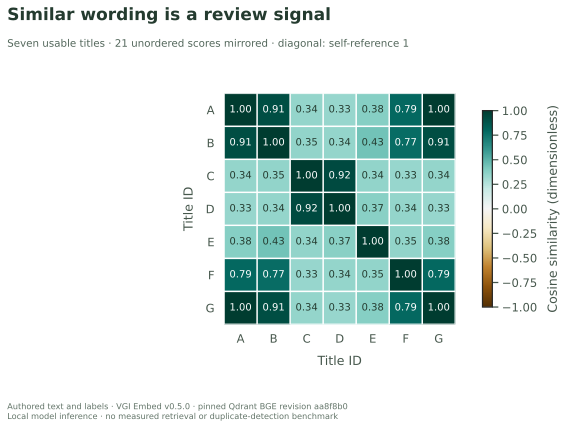

In [10]:
example.matrix(matrix)

In [11]:
%%sql counts <<
WITH roles(role,position) AS (VALUES ('Identical text',1),('Authored paraphrase',2),('Related task',3),('Other pairing',4))
SELECT roles.role, count(p.score) AS all_pairs,count(p.score) FILTER(WHERE p.flagged) AS flagged,
 count(p.score) FILTER(WHERE NOT p.flagged) AS below_threshold
FROM roles LEFT JOIN review_pairs p ON roles.role=p.authored_role GROUP BY roles.role,roles.position ORDER BY roles.position;

### Keep the full pair population and zero categories

Each bar is one mutually exclusive authored role. Its two parts count pairs that meet the threshold and pairs below it; all four roles remain visible even when none are flagged. This exposes whether the chosen cutoff also admits the related-but-different password task. The split is a review workload on this tiny authored collection, not a false-positive rate or evidence of calibrated duplicate detection.

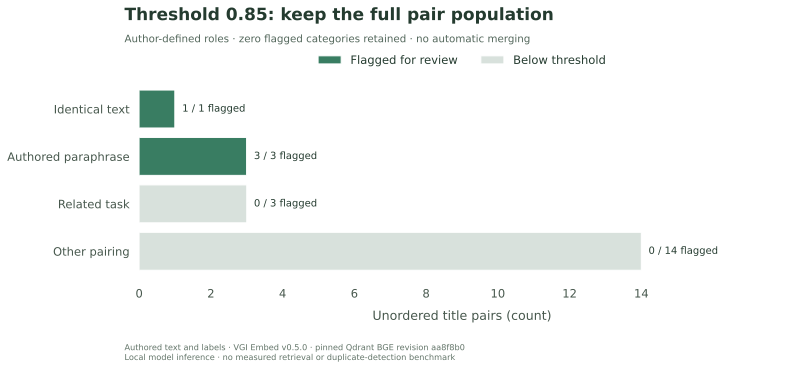

In [12]:
example.counts(counts, REVIEW_THRESHOLD)

In [13]:
%%sql chosen <<
SELECT left_id,right_id,left_title,right_title,authored_role,score FROM review_pairs WHERE flagged ORDER BY score DESC,left_id,right_id;

In [14]:
display(chosen)
assert counts.all_pairs.sum()==21 and (counts.flagged+counts.below_threshold).equals(counts.all_pairs)
prose(f"At cosine **{REVIEW_THRESHOLD:.2f}**, **{int(counts.flagged.sum())} of {int(counts.all_pairs.sum())} pairs** are flagged for reading. Of those, **{int(counts.loc[counts.role=='Related task','flagged'].iloc[0])}** have the author's related-but-different task label. Read both titles before deciding whether any records should be treated alike; no merging is performed.")
export=Path("artifacts/data/02");export.mkdir(parents=True,exist_ok=True)
counts.to_csv(export/"counts.csv",index=False)
chosen.to_csv(export/"chosen.csv",index=False)
con.execute("SELECT * FROM review_pairs ORDER BY left_id,right_id").df().to_csv(export/"pairs.csv",index=False)

,left_id,right_id,left_title,right_title,authored_role,score
0,A,G,How to reset a forgotten password,How to reset a forgotten password,Identical text,1.000000
1,C,D,Quarterly revenue grew by twelve percent,Revenue increased 12% this quarter,Authored paraphrase,0.924801
2,A,B,How to reset a forgotten password,Steps for resetting your lost password,Authored paraphrase,0.910453
3,B,G,Steps for resetting your lost password,How to reset a forgotten password,Authored paraphrase,0.910453


At cosine **0.85**, **4 of 21 pairs** are flagged for reading. Of those, **0** have the author's related-but-different task label. Read both titles before deciding whether any records should be treated alike; no merging is performed.

### Check the numerical and population contracts

The checks reconcile the 21-pair denominator, unique identities, registry width, finite scores, self-similarity and exact-text agreement. Invalid vector controls distinguish undefined cosine (NULL/empty/mismatched/zero magnitude) from a valid orthogonal cosine of zero. They test arithmetic contracts, not authored paraphrase truth.

In [15]:
%%sql checks <<
SELECT 'eight inputs, seven vectors and one explicit missing row' AS invariant,(SELECT count(*)=8 AND count(vec)=7 AND count(*) FILTER(WHERE body IS NULL AND vec IS NULL)=1 FROM vectors) AS passed
UNION ALL SELECT 'model and vector dimensions agree',(SELECT bool_and(len(vec)=registry_dimension AND model='BAAI/bge-small-en-v1.5') FROM vectors WHERE vec IS NOT NULL)
UNION ALL SELECT 'all unordered pairs appear exactly once',(SELECT count(*)=21 AND count(*)=count(DISTINCT(left_id,right_id)) AND bool_and(left_id<right_id) FROM pairs)
UNION ALL SELECT 'cosines are finite and in range',(SELECT bool_and(isfinite(score) AND abs(score)<=1+1e-6) FROM pairs)
UNION ALL SELECT 'worker self similarity is one',(SELECT bool_and(abs(embed.main.similarity(vec,vec)-1)<1e-6) FROM vectors WHERE vec IS NOT NULL)
UNION ALL SELECT 'identical strings have cosine one',(SELECT bool_and(abs(score-1)<1e-6) FROM pairs WHERE authored_role='Identical text')
UNION ALL SELECT 'flagged pairs exactly meet the declared threshold',(SELECT bool_and(flagged=(score>={{REVIEW_THRESHOLD}})) FROM review_pairs)
UNION ALL SELECT 'empty and mismatched vectors have undefined cosine',embed.main.similarity([]::FLOAT[],[1]::FLOAT[]) IS NULL AND embed.main.similarity([1]::FLOAT[],[1,2]::FLOAT[]) IS NULL
UNION ALL SELECT 'zero magnitude and NULL vectors have undefined cosine',embed.main.similarity([0,0]::FLOAT[],[1,2]::FLOAT[]) IS NULL AND embed.main.similarity(NULL::FLOAT[],[1,2]::FLOAT[]) IS NULL
UNION ALL SELECT 'orthogonal vectors have valid zero cosine',abs(embed.main.similarity([1,0]::FLOAT[],[0,1]::FLOAT[]))<1e-6;

In [16]:
display(checks)
assert len(checks)==10 and checks.passed.fillna(False).all()
prose(f"**All {len(checks)} numerical and population checks pass.** Undefined comparisons remain NULL; a finite zero score is a valid comparison, not a missing row.")

,invariant,passed
0,"eight inputs, seven vectors and one explicit m...",True
1,model and vector dimensions agree,True
2,all unordered pairs appear exactly once,True
3,cosines are finite and in range,True
4,worker self similarity is one,True
5,identical strings have cosine one,True
6,flagged pairs exactly meet the declared threshold,True
7,empty and mismatched vectors have undefined co...,True
8,zero magnitude and NULL vectors have undefined...,True
9,orthogonal vectors have valid zero cosine,True


**All 10 numerical and population checks pass.** Undefined comparisons remain NULL; a finite zero score is a valid comparison, not a missing row.

### Focused experiment: lower the review threshold

Change only **`REVIEW_THRESHOLD` from 0.85 to 0.70**, restart and run all. The seven vectors and 21 unordered comparisons stay fixed, within numerical tolerance. The score map should stay unchanged, while flagged pairs can only increase. Inspect whether additional pairs include the related password task or other authored categories.

No universally correct cutoff follows from these titles. The parameter controls which pairs a person reads; it does not authorize automatic deletion, clustering or equivalence. Restore **0.85** for the saved baseline; the README runner saves the experiment separately.

In [17]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
session.close()
assets.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-embed](https://github.com/Query-farm/vgi-embed)